# Newton's Method for House Price Model Optimization

## Real-world problem
A real-estate team wants to predict property sale prices using floor area, bedroom count, and property age. This notebook demonstrates how **Newton's Method** can optimize a linear regression model by using both the gradient and Hessian of its loss function.

**Dataset note:** The notebook creates a reproducible simulated housing dataset. It is intended for learning optimization, not for actual property valuation.

### Learning objectives
- Understand Newton's update using the gradient and Hessian.
- Fit a multivariable linear regression model.
- Track convergence of the loss function.
- Evaluate predictions on held-out test data.
- Compare a manual Newton implementation with SciPy's optimization tools.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.optimize import minimize

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
plt.rcParams["figure.figsize"] = (8, 5)

### Create a sample housing dataset

The target is price in thousands of dollars. In this simulated dataset, larger homes generally cost more, bedroom count contributes to price, older homes receive a modest age-related discount, and random noise represents unobserved factors.

In [2]:
n_samples = 600

area_sqft = rng.uniform(600, 3500, n_samples)
bedrooms = np.clip(np.round(area_sqft / 650 + rng.normal(0, 0.8, n_samples)), 1, 6)
age_years = rng.uniform(0, 50, n_samples)
noise = rng.normal(0, 25, n_samples)

price_thousands = 45 + 0.16 * area_sqft + 12 * bedrooms - 0.8 * age_years + noise

housing = pd.DataFrame({
    "area_sqft": area_sqft,
    "bedrooms": bedrooms.astype(int),
    "age_years": age_years,
    "price_thousands": price_thousands
})

display(housing.head())
print(f"Rows: {len(housing)}")
print(f"Mean simulated price: ${housing['price_thousands'].mean():,.1f} thousand")

,area_sqft,bedrooms,age_years,price_thousands
0,2844.472541,5,19.268474,533.416216
1,1872.747475,3,13.534838,371.612167
2,3089.933968,5,26.095924,546.129166
3,2622.367284,2,15.737481,518.641075
4,873.114309,1,28.204757,202.122001


Rows: 600
Mean simulated price: $387.7 thousand


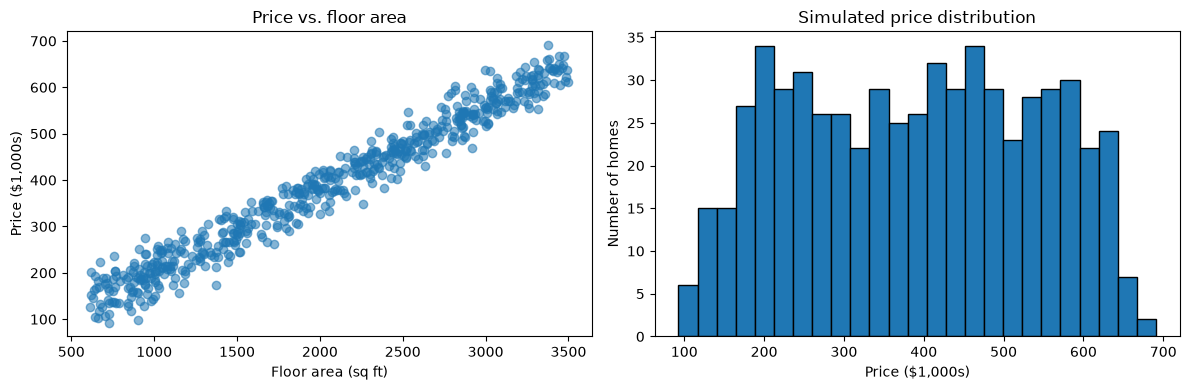

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(housing["area_sqft"], housing["price_thousands"], alpha=0.55)
axes[0].set_xlabel("Floor area (sq ft)")
axes[0].set_ylabel("Price ($1,000s)")
axes[0].set_title("Price vs. floor area")

axes[1].hist(housing["price_thousands"], bins=25, edgecolor="black")
axes[1].set_xlabel("Price ($1,000s)")
axes[1].set_ylabel("Number of homes")
axes[1].set_title("Simulated price distribution")
plt.tight_layout()
plt.show()

### Prepare the data

We split the data before fitting the scaler to avoid leaking information from the test set. Standardizing the features improves numerical conditioning and makes optimization more stable.

In [4]:
features = ["area_sqft", "bedrooms", "age_years"]
X = housing[features].to_numpy(dtype=float)
y = housing["price_thousands"].to_numpy(dtype=float)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_b = np.c_[np.ones(len(X_train_scaled)), X_train_scaled]
X_test_b = np.c_[np.ones(len(X_test_scaled)), X_test_scaled]

print("Training examples:", len(X_train))
print("Test examples:", len(X_test))
print("Parameters to optimize (intercept + features):", X_train_b.shape[1])

Training examples: 480
Test examples: 120
Parameters to optimize (intercept + features): 4



### Newton's Method for Linear Regression

For parameter vector $\theta$, use the half mean-squared-error objective:

$$
J(\theta) = \frac{1}{2m}(X\theta-y)^T(X\theta-y)
$$

The gradient is

$$
\nabla J(\theta) = \frac{1}{m}X^T(X\theta-y)
$$

and the Hessian is

$$
H(\theta) = \frac{1}{m}X^TX
$$

Newton's update is

$$
\theta_{t+1} = \theta_t - H(\theta_t)^{-1}\nabla J(\theta_t)
$$

In code, solve the linear system rather than explicitly calculating the inverse. For this squared-error linear regression problem, the Hessian is constant. Newton's Method reaches the least-squares solution in one full update when the Hessian is nonsingular, aside from floating-point effects.

In [5]:
def cost_function(theta, X, y):
    errors = X @ theta - y
    return float(errors @ errors / (2 * len(y)))


def gradient(theta, X, y):
    return X.T @ (X @ theta - y) / len(y)


def hessian(X):
    return X.T @ X / len(X)


def newtons_method(X, y, iterations=10, tolerance=1e-8):
    theta = np.zeros(X.shape[1], dtype=float)
    H = hessian(X)
    cost_history = [cost_function(theta, X, y)]

    for _ in range(iterations):
        grad = gradient(theta, X, y)
        # Solve H * step = gradient; avoid explicitly computing H inverse.
        step = np.linalg.solve(H, grad)
        theta = theta - step
        cost_history.append(cost_function(theta, X, y))

        if np.linalg.norm(grad, ord=2) < tolerance:
            break

    return theta, cost_history


theta, cost_history = newtons_method(X_train_b, y_train)

print("Newton's Method parameters:")
print(f"Intercept: {theta[0]:.2f} thousand dollars")
for name, weight in zip(features, theta[1:]):
    print(f"{name}: {weight:.2f} thousand dollars per standardized unit")
print(f"Final training cost (half-MSE): {cost_history[-1]:.6f}")
print(f"Newton updates performed: {len(cost_history) - 1}")

Newton's Method parameters:
Intercept: 390.56 thousand dollars
area_sqft: 137.14 thousand dollars per standardized unit
bedrooms: 14.87 thousand dollars per standardized unit
age_years: -13.07 thousand dollars per standardized unit
Final training cost (half-MSE): 309.116011
Newton updates performed: 2


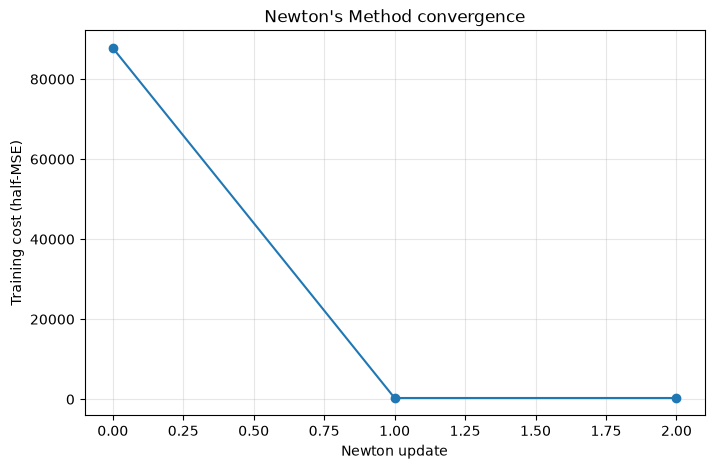

In [6]:
plt.plot(range(len(cost_history)), cost_history, marker="o")
plt.xlabel("Newton update")
plt.ylabel("Training cost (half-MSE)")
plt.title("Newton's Method convergence")
plt.grid(True, alpha=0.3)
plt.show()

### Evaluate predictions on unseen properties

We evaluate the model on data not used for fitting. MAE and RMSE are reported in thousands of dollars; R² measures the proportion of variance explained.

In [7]:
y_pred = X_test_b @ theta

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Test MAE:  ${mae:.2f} thousand")
print(f"Test RMSE: ${rmse:.2f} thousand")
print(f"Test R²:   {r2:.3f}")

Test MAE:  $21.15 thousand
Test RMSE: $25.87 thousand
Test R²:   0.969


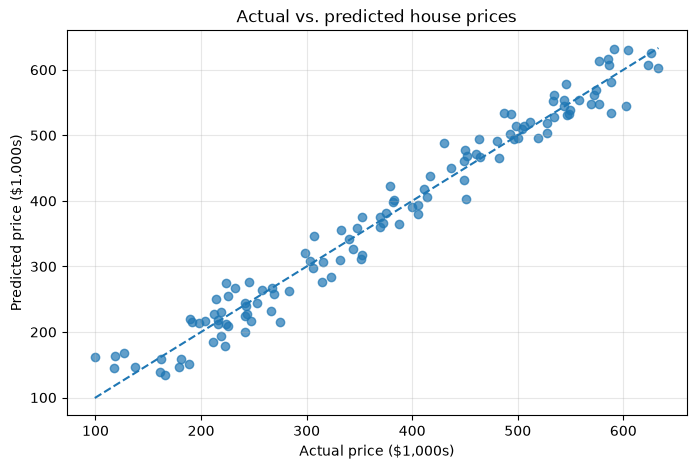

In [8]:
plt.scatter(y_test, y_pred, alpha=0.7)
lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())
plt.plot([lower, upper], [lower, upper], linestyle="--")
plt.xlabel("Actual price ($1,000s)")
plt.ylabel("Predicted price ($1,000s)")
plt.title("Actual vs. predicted house prices")
plt.grid(True, alpha=0.3)
plt.show()

### Predict the price of a hypothetical property

The function below applies the same fitted scaler and optimized parameters to a new property.

In [10]:
def predict_house_price(area_sqft, bedrooms, age_years):
    new_home = np.array([[area_sqft, bedrooms, age_years]], dtype=float)
    new_home_scaled = scaler.transform(new_home)
    new_home_b = np.c_[np.ones(len(new_home_scaled)), new_home_scaled]
    return float((new_home_b @ theta).item())


example_area = 1800
example_bedrooms = 3
example_age = 10

predicted_price = predict_house_price(example_area, example_bedrooms, example_age)

print("Hypothetical property")
print(f"Area: {example_area:,} sq ft")
print(f"Bedrooms: {example_bedrooms}")
print(f"Age: {example_age} years")
print(f"Estimated price: ${predicted_price:,.1f} thousand")

Hypothetical property
Area: 1,800 sq ft
Bedrooms: 3
Age: 10 years
Estimated price: $360.7 thousand


### Validate with SciPy's optimizer

`scipy.optimize.minimize` can optimize the same objective using a Newton-CG method. We provide the analytical gradient and Hessian-vector product. For Newton-CG, `hessp` is a function that computes the Hessian multiplied by a vector.

In [11]:
def hessian_vector_product(theta, vector, X, y):
    return hessian(X) @ vector


result = minimize(
    fun=lambda params: cost_function(params, X_train_b, y_train),
    x0=np.zeros(X_train_b.shape[1]),
    method="Newton-CG",
    jac=lambda params: gradient(params, X_train_b, y_train),
    hessp=lambda params, vector: hessian_vector_product(
        params, vector, X_train_b, y_train
    ),
    options={"xtol": 1e-8, "maxiter": 100}
)

scipy_pred = X_test_b @ result.x

comparison = pd.DataFrame({
    "Model": ["Manual Newton's Method", "SciPy Newton-CG"],
    "MAE ($1,000s)": [
        mean_absolute_error(y_test, y_pred),
        mean_absolute_error(y_test, scipy_pred)
    ],
    "RMSE ($1,000s)": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, scipy_pred))
    ],
    "R²": [
        r2_score(y_test, y_pred),
        r2_score(y_test, scipy_pred)
    ]
})

print("SciPy optimizer success:", result.success)
print("SciPy message:", result.message)
display(comparison.round(4))

SciPy optimizer success: True
SciPy message: Optimization terminated successfully.


,Model,"MAE ($1,000s)","RMSE ($1,000s)",R²
0,Manual Newton's Method,21.1526,25.865,0.9686
1,SciPy Newton-CG,21.1526,25.865,0.9686


### interpretation and limitations

- Newton's Method uses curvature information from the Hessian, which can reduce the number of optimization steps.
- Computing or solving with the Hessian can be expensive for models with many parameters. For this small linear regression model, the Hessian is easy to compute.
- The Hessian must be nonsingular for the direct update used here; poorly conditioned or non-convex problems may require damping or other safeguards.
- The data is simulated. Real-world valuation would require reliable transaction data, location, property condition, and careful out-of-sample validation.
- Strong test performance on synthetic data does not establish that the model is suitable for real financial or property decisions.

### Key takeaway
Newton's Method can converge rapidly by using both slope and curvature. This example applies that idea to a practical regression objective: minimizing the error in house-price predictions.